In [4]:
!pip install scikit-learn pandas numpy matplotlib seaborn


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\USER\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [6]:
# ==========================================
# STAGE 2 — MACHINE LEARNING (UNSUPERVISED & SUPERVISED)
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns     
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Đọc file dữ liệu sạch từ Stage 1
df = pd.read_csv('Master_Stage1.csv')
print("Kích thước dữ liệu đầu vào Stage 2:", df.shape)
display(df.head())

ModuleNotFoundError: No module named 'sklearn'

Số chiều cần thiết để giữ lại >= 85% phương sai: 6


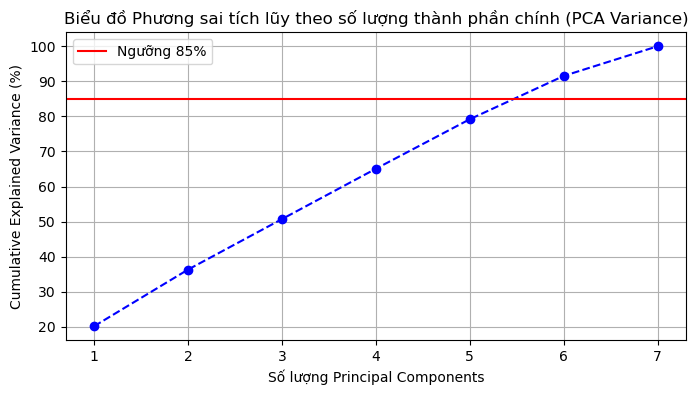

In [ ]:
# ==========================================
# TASK 1: UNSUPERVISED LEARNING & PCA (VÕ HÀ MINH THẮNG)
# ==========================================
features = [
    "CGPA",
    "Sleep_Duration",
    "Study_Hours",
    "Social_Media_Hours",
    "Physical_Activity",
    "Stress_Level",
    "Extracurricular_Hours",
]

# Lọc các cột số cần thiết và drop giá trị thiếu
df_task1 = df[features].dropna().copy()

# 1. Chuẩn hóa dữ liệu
X_scaled = StandardScaler().fit_transform(df_task1)

# 2. Tính toán phương sai tích lũy
X_pca_full = PCA().fit(X_scaled)
cum_variance = np.cumsum(X_pca_full.explained_variance_ratio_)

# Tìm số chiều tối thiểu để giữ lại từ 85% đến 95% phương sai
n_components = np.argmax(cum_variance >= 0.85) + 1
print(f"Số chiều cần thiết để giữ lại >= 85% phương sai: {n_components}")

# Biểu đồ phương sai tích lũy
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(cum_variance) + 1), cum_variance * 100, marker="o", linestyle="--", color="b")
plt.axhline(y=85, color="r", linestyle="-", label="Ngưỡng 85%")
plt.xlabel("Số lượng Principal Components")
plt.ylabel("Cumulative Explained Variance (%)")
plt.title("Biểu đồ Phương sai tích lũy theo số lượng thành phần chính (PCA Variance)")
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
# 3. Chạy PCA giảm xuống 2 chiều để vẽ biểu đồ phân cụm 2D trực quan
pca_2d = PCA(n_components=2)
X_pca = pca_2d.fit_transform(X_scaled)

c:\Users\minht\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\minht\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\Users\minht\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\minht\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^

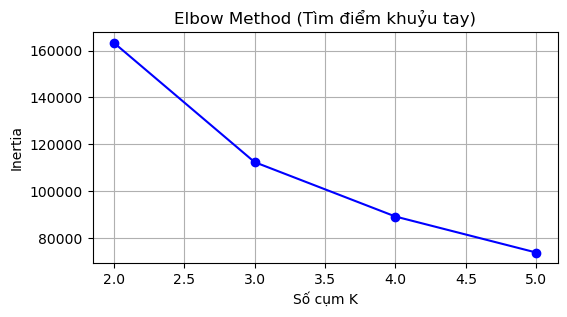

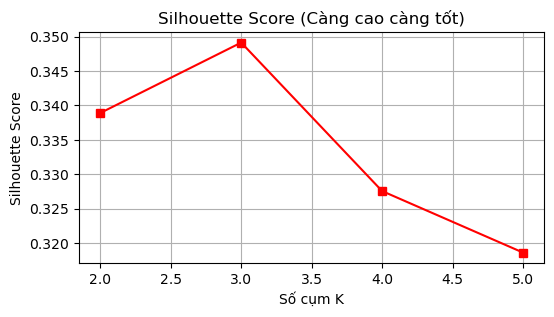

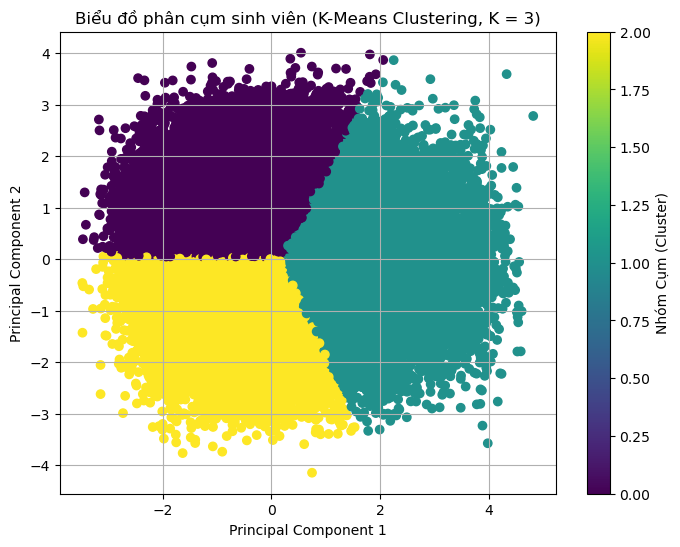

Đã xuất file phân cụm thành công: Master_Dataset_Clustered_Standard.csv


In [ ]:
# ==========================================
# TASK 2: K-MEANS CLUSTERING & PHÂN CỤM SINH VIÊN (VÕ HÀ MINH THẮNG)
# ==========================================
from sklearn.metrics import silhouette_score

inertias = []
silhouette_scores = []
K_range = range(2, 6)

# Lấy mẫu ngẫu nhiên để tính silhouette nhanh hơn
sample_idx = np.random.choice(X_pca.shape[0], size=min(3000, X_pca.shape[0]), replace=False)
X_pca_sample = X_pca[sample_idx]

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_pca)
    inertias.append(km.inertia_)
    labels_sample = km.predict(X_pca_sample)
    silhouette_scores.append(silhouette_score(X_pca_sample, labels_sample))

# Biểu đồ Elbow Method
plt.figure(figsize=(6, 3))
plt.plot(K_range, inertias, "b-o")
plt.title("Elbow Method (Tìm điểm khuỷu tay)")
plt.xlabel("Số cụm K")
plt.ylabel("Inertia")
plt.grid(True)
plt.show()

# Biểu đồ Silhouette Score
plt.figure(figsize=(6, 3))
plt.plot(K_range, silhouette_scores, "r-s")
plt.title("Silhouette Score (Càng cao càng tốt)")
plt.xlabel("Số cụm K")
plt.ylabel("Silhouette Score")
plt.grid(True)
plt.show()

# Chạy K-Means với K = 3 nhóm
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(X_pca)

# Gắn nhãn cụm vào bảng dữ liệu và lưu file
df_task1["Cluster_Label"] = cluster_labels
df_task1.to_csv("Master_Dataset_Clustered_Standard.csv", index=False)

# Vẽ biểu đồ phân cụm 2D
plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=cluster_labels, cmap="viridis")
plt.title("Biểu đồ phân cụm sinh viên (K-Means Clustering, K = 3)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(label="Nhóm Cụm (Cluster)")
plt.grid(True)
plt.show()
print("Đã xuất file phân cụm thành công: Master_Dataset_Clustered_Standard.csv");

[Linear Regression] 
- MSE: 0.2791 
- RMSE: 0.5283 
- R2 Score: 0.0162

[Decision Tree Regressor] 
- MSE: 0.5527 
- RMSE: 0.7435 
- R2 Score: -0.9484



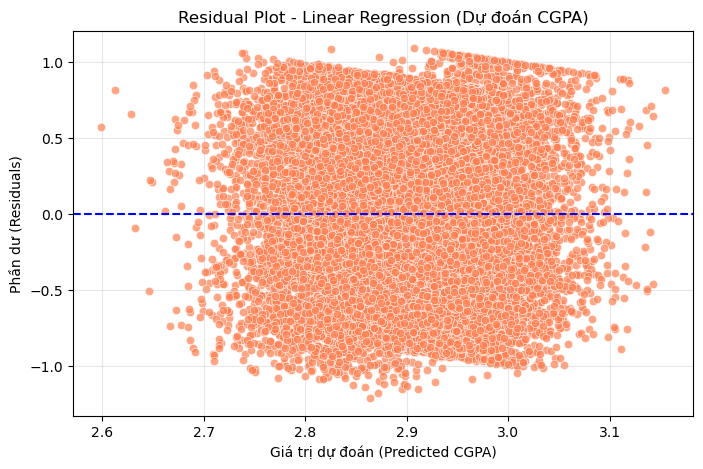

[Logistic Regression]
Classification Report:
               precision    recall  f1-score   support

           0       0.91      0.59      0.72     17995
           1       0.11      0.46      0.18      2005

    accuracy                           0.58     20000
   macro avg       0.51      0.53      0.45     20000
weighted avg       0.83      0.58      0.66     20000



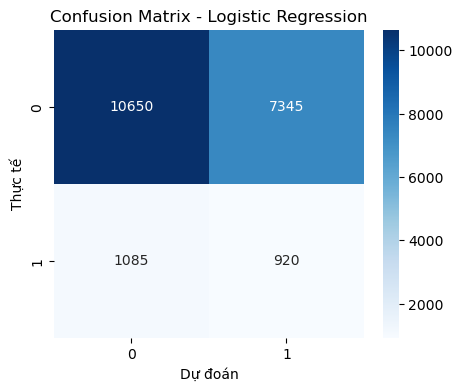

[Decision Tree Classifier]
Classification Report:
               precision    recall  f1-score   support

           0       0.90      0.90      0.90     17995
           1       0.12      0.12      0.12      2005

    accuracy                           0.82     20000
   macro avg       0.51      0.51      0.51     20000
weighted avg       0.82      0.82      0.82     20000



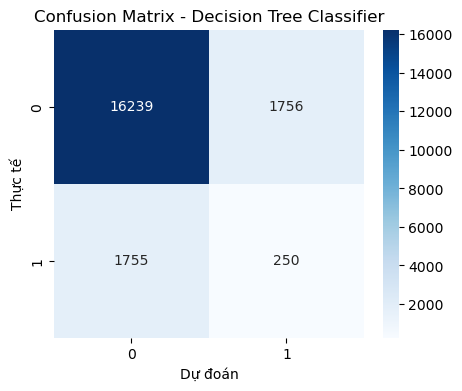

In [ ]:
# ==========================================
# TASK 3 & TASK 4: SUPERVISED LEARNING (NGUYỄN TUẤN VŨ)
# ==========================================
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.metrics import mean_squared_error, r2_score, classification_report, confusion_matrix

df_sup = df.dropna().copy()

# --- TASK 3: REGRESSION - DỰ ĐOÁN ĐIỂM CGPA ---
X_reg = df_sup.select_dtypes(include=['float64', 'int64']).drop(columns=['CGPA', 'Depression'], errors='ignore')
y_reg = df_sup['CGPA']

X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(X_reg, y_reg, test_size=0.2, random_state=42)

# Linear Regression & Decision Tree Regressor
lr_model = LinearRegression().fit(X_train_r, y_train_r)
y_pred_lr = lr_model.predict(X_test_r)

dt_reg_model = DecisionTreeRegressor(random_state=42).fit(X_train_r, y_train_r)
y_pred_dt_reg = dt_reg_model.predict(X_test_r)

def evaluate_regression(y_true, y_pred, model_name):
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    print(f"[{model_name}] \n- MSE: {mse:.4f} \n- RMSE: {rmse:.4f} \n- R2 Score: {r2:.4f}\n")

evaluate_regression(y_test_r, y_pred_lr, "Linear Regression")
evaluate_regression(y_test_r, y_pred_dt_reg, "Decision Tree Regressor")

# Vẽ Residual Plot cho Linear Regression
plt.figure(figsize=(8, 5))
residuals = y_test_r - y_pred_lr
sns.scatterplot(x=y_pred_lr, y=residuals, color='coral', alpha=0.7)
plt.axhline(y=0, color='blue', linestyle='--')
plt.title('Residual Plot - Linear Regression (Dự đoán CGPA)')
plt.xlabel('Giá trị dự đoán (Predicted CGPA)')
plt.ylabel('Phần dư (Residuals)')
plt.grid(True, alpha=0.3)
plt.show()

# --- TASK 4: CLASSIFICATION - DỰ ĐOÁN TRẠNG THÁI TRẦM CẢM ---
if 'Depression' not in df_sup.columns:
    df_sup['Depression'] = (df_sup['CGPA'] < 2.5).astype(int)

X_cls = df_sup.select_dtypes(include=['float64', 'int64']).drop(columns=['Depression', 'CGPA'], errors='ignore')
y_cls = df_sup['Depression']

X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(X_cls, y_cls, test_size=0.2, random_state=42)

log_model = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42).fit(X_train_c, y_train_c)
y_pred_log = log_model.predict(X_test_c)

dt_cls_model = DecisionTreeClassifier(class_weight='balanced', random_state=42).fit(X_train_c, y_train_c)
y_pred_dt_cls = dt_cls_model.predict(X_test_c)

def evaluate_classification(y_true, y_pred, model_name):
    print(f"[{model_name}]")
    print("Classification Report:\n", classification_report(y_true, y_pred, zero_division=0))
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title(f'Confusion Matrix - {model_name}')
    plt.xlabel('Dự đoán')
    plt.ylabel('Thực tế')
    plt.show()

evaluate_classification(y_test_c, y_pred_log, "Logistic Regression")
evaluate_classification(y_test_c, y_pred_dt_cls, "Decision Tree Classifier")